# What 74 scenic road trips look like in data

Byway ships 74 ready-made trips on every continent. Each one was planned by an LLM, snapped to real roads, and measured
with OpenRouteService (scenic route and fastest route). This notebook treats that set as a dataset and asks:

1. How long are the trips, and how hard are the driving days?
2. How much slower is the scenic route than the fastest one, and what does that detour cost?
3. Do regions differ in road type (highway, unpaved) and climbing?
4. Can trip length be predicted from distance and terrain, and do trips fall into natural groups?

Source: `data/presets.json` (OpenRouteService routing, OpenStreetMap road data).

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

with open("../data/presets.json", encoding="utf-8") as f:
    raw = list(json.load(f).values())
len(raw)

74

## 1. Build a tidy table: one row per trip

Countries come from a point-in-polygon lookup of every stop against the app's own country outlines
(`public/countries.json`, Natural Earth, public domain), not from guessed coordinate boxes. A trip's region is the
region of its start.

In [2]:
from shapely.geometry import shape, Point
from shapely.strtree import STRtree

with open("../public/countries.json", encoding="utf-8") as f:
    feats = json.load(f)["features"]
geoms = [shape(x["geometry"]) for x in feats]
codes = [x["properties"]["cc"] for x in feats]
tree = STRtree(geoms)

def country(lat, lng):
    p = Point(lng, lat)
    for i in tree.query(p):
        if geoms[i].contains(p): return codes[i]
    i = tree.nearest(p)                       # a coastal point just outside the simplified outline
    return codes[i] if geoms[i].distance(p) < 0.5 else None

REGION = {**dict.fromkeys(["US", "CA", "MX"], "North America"), "CR": "Central America",
          **dict.fromkeys(["AR", "BO", "BR", "CL", "PE"], "South America"),
          **dict.fromkeys(["AT", "CH", "ES", "FR", "GB", "HR", "IE", "IS", "IT", "NO", "RO"], "Europe"),
          **dict.fromkeys(["AU", "NZ"], "Oceania"), **dict.fromkeys(["BW", "MA", "NA", "ZA"], "Africa"),
          **dict.fromkeys(["OM", "TR"], "Middle East"),
          **dict.fromkeys(["BD", "GE", "IN", "JP", "KR", "MY", "SG", "TH", "TW", "VN"], "Asia")}
def region(lat, lng): return REGION[country(lat, lng)]

In [3]:
rows = []
for t in raw:
    s, f = t["routes"]["scenic"], t["routes"].get("fastest") or {}
    stops = t["stops"]
    first = stops[0]
    days = max(x.get("day", 1) for x in stops)
    # drive hours per day: a leg belongs to the day of the stop it arrives at
    per_day = {}
    for i, leg in enumerate(s["legs"]):
        d = stops[i + 1].get("day", 1)
        per_day[d] = per_day.get(d, 0) + leg["duration_s"] / 3600
    hrs = list(per_day.values())
    km = s["distance_m"] / 1000
    rows.append(dict(
        name=t["name"], topgear=t["name"].startswith("Top Gear"),
        country=country(first["lat"], first["lng"]), region=region(first["lat"], first["lng"]),
        n_countries=len({country(x["lat"], x["lng"]) for x in stops}),
        lat=first["lat"], lng=first["lng"],
        days=days, stops=len(stops), km=km, hours=s["duration_s"] / 3600,
        km_per_day=km / days, max_day_h=max(hrs) if hrs else np.nan,
        mean_day_h=np.mean(hrs) if hrs else np.nan,
        avg_kmh=km / (s["duration_s"] / 3600),
        highway_pct=100 * s.get("highway_m", 0) / s["distance_m"],
        unpaved_pct=100 * s.get("unpaved_m", 0) / s["distance_m"],
        toll_km=s.get("toll_m", 0) / 1000, ferry_km=s.get("ferry_m", 0) / 1000,
        ascent_m=s.get("ascent_m", 0), climb_m_per_km=s.get("ascent_m", 0) / km,
        fast_km=(f.get("distance_m") or np.nan) / 1000, fast_h=(f.get("duration_s") or np.nan) / 3600,
        max_h_setting=t["settings"].get("maxHours"),
    ))
df = pd.DataFrame(rows)
df["detour_km_pct"] = 100 * (df.km / df.fast_km - 1)
df["extra_min"] = 60 * (df.hours - df.fast_h)
df.round(1).head()

,name,topgear,country,region,n_countries,lat,lng,days,stops,km,...,unpaved_pct,toll_km,ferry_km,ascent_m,climb_m_per_km,fast_km,fast_h,max_h_setting,detour_km_pct,extra_min
0,Pacific Coast Highway: San Francisco to Los An...,False,US,North America,1,37.8,-122.4,3,10,946.6,...,1.5,0.0,0.0,14241.6,15.0,809.7,11.2,7.5,16.9,182.9
1,Denver to Moab via the San Juan Skyway,False,US,North America,1,39.7,-105.0,3,10,961.9,...,3.7,0.0,0.0,15716.8,16.3,908.0,11.1,7.5,5.9,159.2
2,Desert Canyons and High Plateaus Loop,False,US,North America,1,36.2,-115.1,4,15,1485.4,...,0.6,17.9,0.0,17240.4,11.6,1046.1,13.6,7.5,42.0,358.4
3,"Grand Teton, Yellowstone and the Beartooth Hig...",False,US,North America,1,43.5,-110.8,3,11,537.6,...,0.0,0.4,0.0,7865.6,14.6,525.2,8.4,7.5,2.4,29.7
4,Glacier National Park Loop from Missoula,False,US,North America,1,46.9,-114.0,3,12,849.6,...,0.0,0.0,0.0,8998.3,10.6,896.6,10.9,7.5,-5.2,20.2


In [4]:
print(df.region.value_counts().to_string())
df.describe().T[["count", "mean", "50%", "min", "max"]].round(1)

region
North America      29
Europe             14
Asia               10
Oceania             8
South America       6
Africa              4
Middle East         2
Central America     1


,count,mean,50%,min,max
n_countries,74.0,1.1,1.0,1.0,2.0
lat,74.0,21.9,35.9,-53.2,64.1
lng,74.0,-12.9,-15.5,-123.4,172.6
days,74.0,5.1,5.0,2.0,14.0
stops,74.0,17.8,16.0,6.0,58.0
km,74.0,1222.0,946.3,261.8,5844.6
hours,74.0,18.2,14.3,4.6,75.4
km_per_day,74.0,232.2,219.3,73.8,451.3
max_day_h,74.0,5.3,5.3,2.8,9.6
mean_day_h,74.0,3.5,3.3,1.5,6.1


## 2. Trip size

The spread of `km_per_day` shows how the planner paces drives.

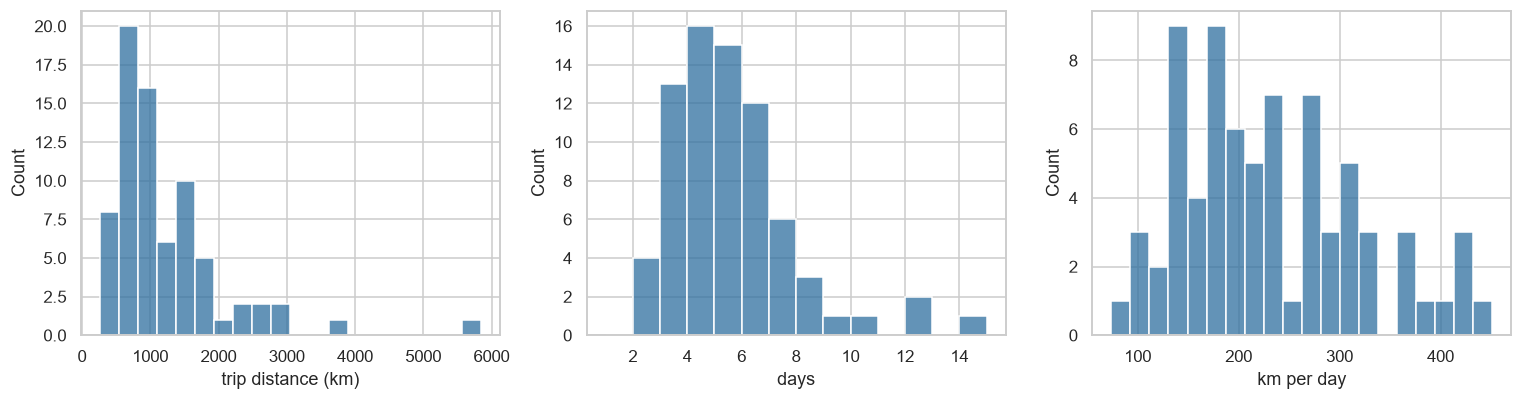

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(df.km, bins=20, ax=ax[0], color="#2f6f9f"); ax[0].set_xlabel("trip distance (km)")
sns.histplot(df.days, bins=range(1, int(df.days.max()) + 2), ax=ax[1], color="#2f6f9f"); ax[1].set_xlabel("days")
sns.histplot(df.km_per_day, bins=20, ax=ax[2], color="#2f6f9f"); ax[2].set_xlabel("km per day")
plt.tight_layout(); plt.show()

## 3. How hard are the driving days?

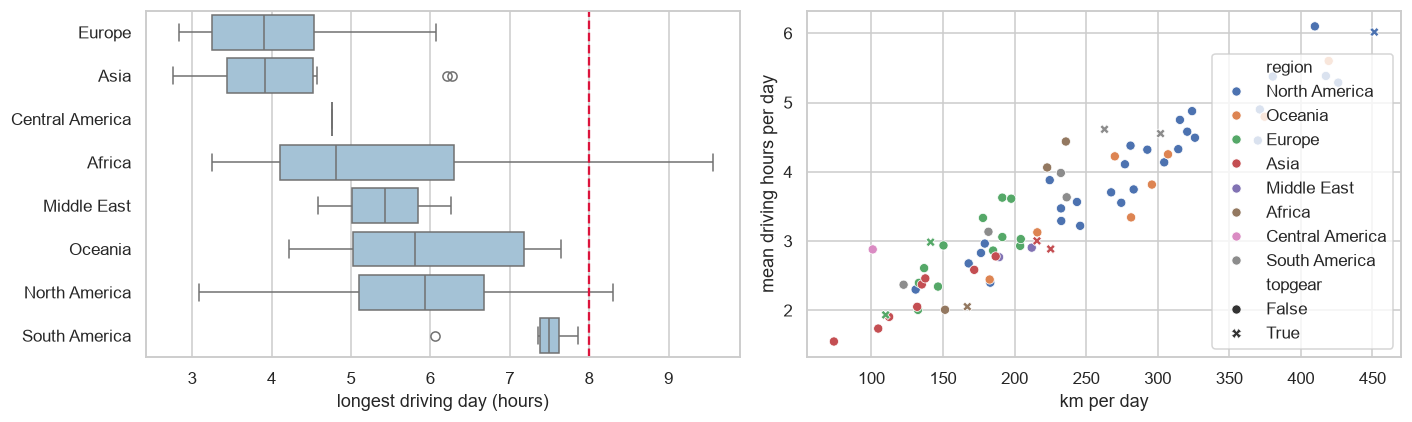

2 of 74 trips have a day longer than 8 hours of driving


,name,region,max_day_h,max_h_setting
65,Namibia Desert and Wildlife Loop,Africa,9.6,NaN
29,Pacific Coast Odyssey: Seattle to San Diego,North America,8.3,7.5


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = df.groupby("region").max_day_h.median().sort_values().index
sns.boxplot(data=df, y="region", x="max_day_h", order=order, ax=ax[0], color="#9cc3de")
ax[0].axvline(8, ls="--", c="crimson"); ax[0].set_xlabel("longest driving day (hours)"); ax[0].set_ylabel("")
sns.scatterplot(data=df, x="km_per_day", y="mean_day_h", hue="region", style="topgear", ax=ax[1])
ax[1].set_xlabel("km per day"); ax[1].set_ylabel("mean driving hours per day")
plt.tight_layout(); plt.show()

hard = df[df.max_day_h > 8][["name", "region", "max_day_h", "max_h_setting"]].sort_values("max_day_h", ascending=False)
print(f"{len(hard)} of {len(df)} trips have a day longer than 8 hours of driving")
hard.round(1).head(10)

Only 2 trips break 8 hours (Namibia, with 41% unpaved road, and the Seattle to San Diego trip). Where a trip carries its
own `maxHours` setting (35 of 74), the longest day sits about 2 hours under it on median, so the planner's day limit holds.

In [7]:
df["over_setting_h"] = df.max_day_h - df.max_h_setting
df.over_setting_h.describe().round(2)

count    35.00
mean     -2.11
std       1.47
min      -4.56
25%      -3.23
50%      -2.07
75%      -1.35
max       0.80
Name: over_setting_h, dtype: float64

## 4. The cost of going scenic

For each trip the app measured both the scenic route and the fastest route between the same stops.

74 trips with both routes
               count   mean    std  min   25%    50%    75%    max
detour_km_pct   74.0   12.8   13.0 -5.2   3.1   11.0   18.0   70.9
extra_min       74.0  167.1  139.1  2.6  79.4  135.9  221.7  696.5


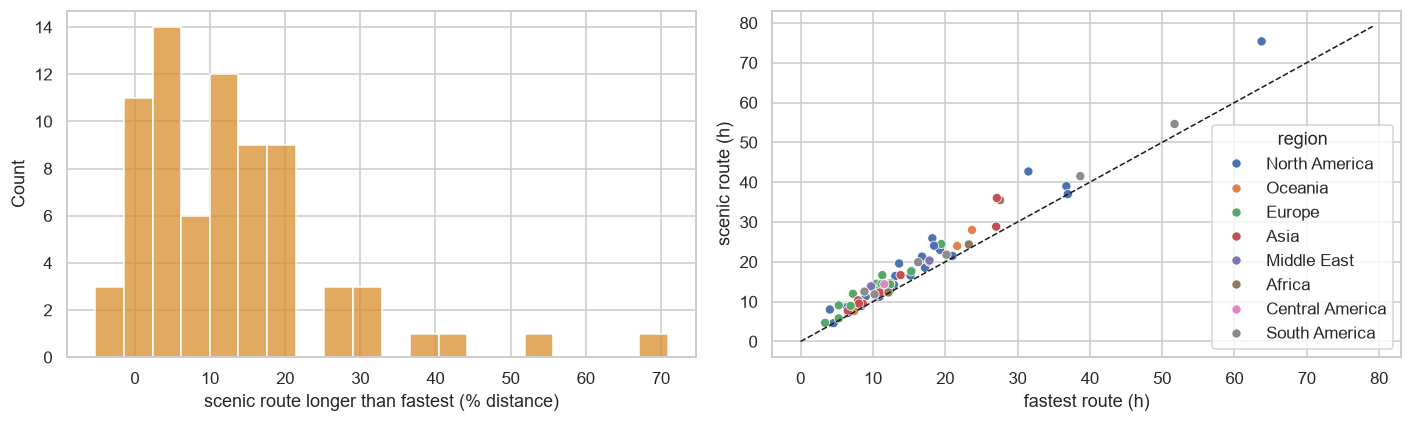

In [8]:
d = df.dropna(subset=["fast_km"])
print(f"{len(d)} trips with both routes")
print(d[["detour_km_pct", "extra_min"]].describe().round(1).T.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(d.detour_km_pct, bins=20, ax=ax[0], color="#d98c2b")
ax[0].set_xlabel("scenic route longer than fastest (% distance)")
sns.scatterplot(data=d, x="fast_h", y="hours", hue="region", ax=ax[1])
lim = [0, max(d.hours.max(), d.fast_h.max()) * 1.05]
ax[1].plot(lim, lim, "k--", lw=1); ax[1].set_xlabel("fastest route (h)"); ax[1].set_ylabel("scenic route (h)")
plt.tight_layout(); plt.show()

In [9]:
d.sort_values("detour_km_pct", ascending=False)[["name", "region", "km", "fast_km", "detour_km_pct", "extra_min"]].round(1).head(8)

,name,region,km,fast_km,detour_km_pct,extra_min
31,Appalachian Ridges and Curves,North America,503.8,294.8,70.9,239.1
26,Lake District and Yorkshire Dales Driving Loop,Europe,613.1,401.4,52.7,228.4
2,Desert Canyons and High Plateaus Loop,North America,1485.4,1046.1,42.0,358.4
37,Wild Atlantic Way: Galway to the Ring of Kerry,Europe,665.8,481.4,38.3,284.8
28,Innsbruck to Lake Como via Stelvio and the Dol...,Europe,765.7,578.4,32.4,240.0
60,Costa Verde and Mountain Climb to São Paulo,South America,727.1,551.6,31.8,222.5
52,6-Day Yucatán Peninsula Cultural and Coastal Loop,North America,1756.5,1348.1,30.3,461.4
63,Montreal and Gaspé Peninsula Coastal Loop,North America,2868.4,2242.0,27.9,671.7


## 5. Road type and terrain by region

In [10]:
g = df.groupby("region").agg(trips=("name", "count"), km=("km", "median"),
        highway_pct=("highway_pct", "median"), unpaved_pct=("unpaved_pct", "median"),
        climb_m_per_km=("climb_m_per_km", "median"), avg_kmh=("avg_kmh", "median")).round(1)
g.sort_values("climb_m_per_km", ascending=False)

,trips,km,highway_pct,unpaved_pct,climb_m_per_km,avg_kmh
region,,,,,,
Central America,1,605.6,0.0,7.0,24.5,42.1
Asia,10,710.9,11.5,0.0,21.8,62.4
Europe,14,724.9,19.7,0.1,18.7,56.2
South America,6,1290.1,1.7,9.6,15.2,58.2
Oceania,8,1008.7,12.2,0.1,13.9,74.8
Middle East,2,1215.0,15.6,1.8,12.8,70.7
North America,29,1108.4,27.0,0.1,11.6,70.7
Africa,4,1169.4,1.7,0.3,8.9,65.1


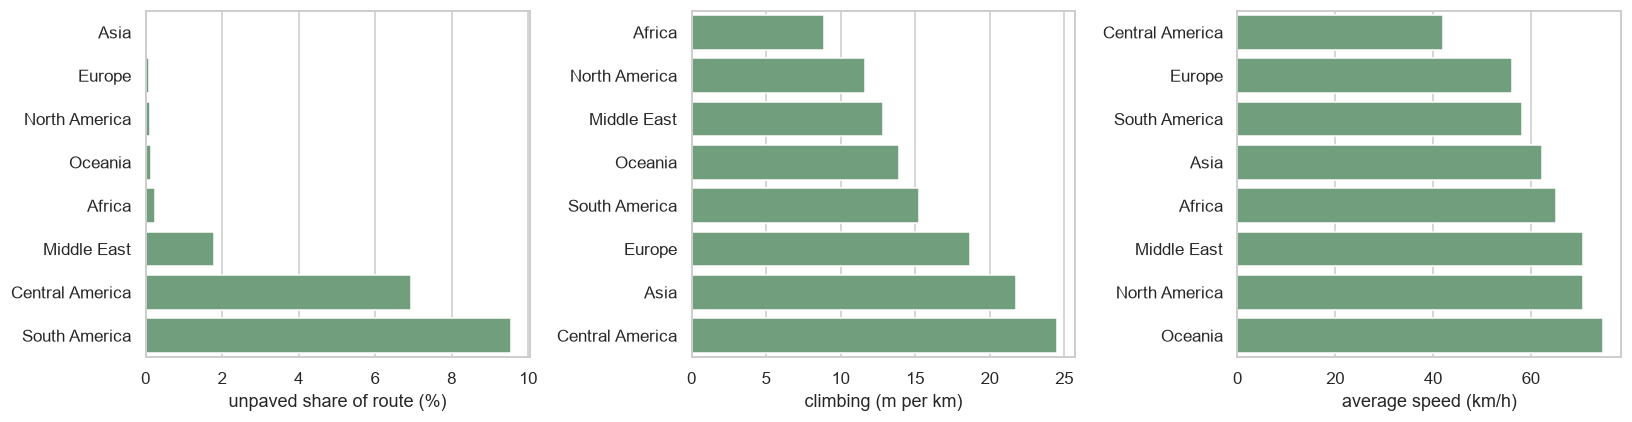

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, ttl in zip(ax, ["unpaved_pct", "climb_m_per_km", "avg_kmh"],
                       ["unpaved share of route (%)", "climbing (m per km)", "average speed (km/h)"]):
    o = df.groupby("region")[col].median().sort_values().index
    sns.barplot(data=df, y="region", x=col, order=o, estimator=np.median, errorbar=None, ax=a, color="#6aa57a")
    a.set_xlabel(ttl); a.set_ylabel("")
plt.tight_layout(); plt.show()

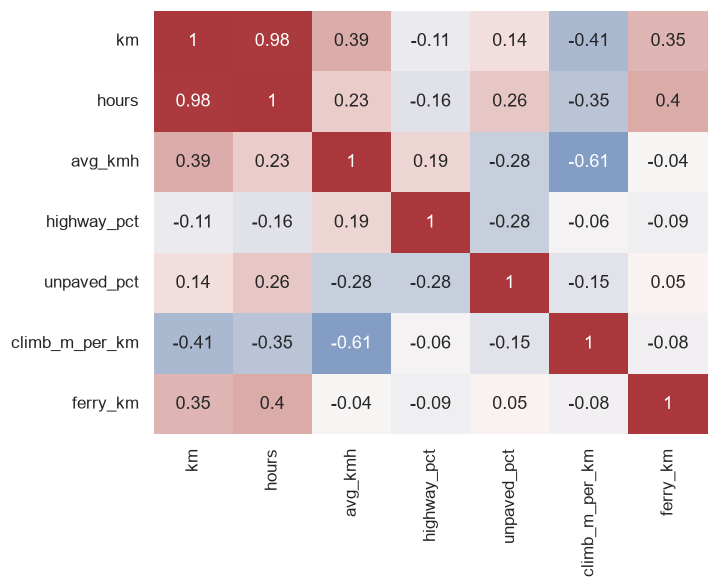

In [12]:
corr = df[["km", "hours", "avg_kmh", "highway_pct", "unpaved_pct", "climb_m_per_km", "ferry_km"]].corr().round(2)
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, cmap="vlag", center=0, cbar=False); plt.show()

## 6. Predicting drive time

How well do distance and terrain explain driving time? A linear model with cross validation, then a random forest to see
whether non-linear effects (gravel, mountains) matter. With only 74 trips the numbers are rough.

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold

X = df[["km", "highway_pct", "unpaved_pct", "climb_m_per_km", "ferry_km"]].fillna(0)
y = df.hours
cv = KFold(5, shuffle=True, random_state=0)
models = {"distance only": (LinearRegression(), ["km"]),
          "linear + terrain": (LinearRegression(), list(X.columns)),
          "random forest": (RandomForestRegressor(300, random_state=0, min_samples_leaf=2), list(X.columns))}
for name, (m, cols) in models.items():
    r2 = cross_val_score(m, X[cols], y, cv=cv, scoring="r2")
    mae = -cross_val_score(m, X[cols], y, cv=cv, scoring="neg_mean_absolute_error")
    print(f"{name:18s} R2 {r2.mean():.3f}   MAE {mae.mean():.2f} h")

distance only      R2 0.941   MAE 1.85 h
linear + terrain   R2 0.969   MAE 1.34 h


random forest      R2 0.864   MAE 2.36 h


Distance alone gives R2 of about 0.94 and adding terrain lifts it to about 0.97. The random forest does worse than the
linear model: with 74 rows and a few extreme trips (Cross-Canada at 5,800 km) a tree model cannot extrapolate, and the
linear fit is the better choice here. The largest miss is Cross-Canada, whose long straight highway is faster than its
distance suggests.

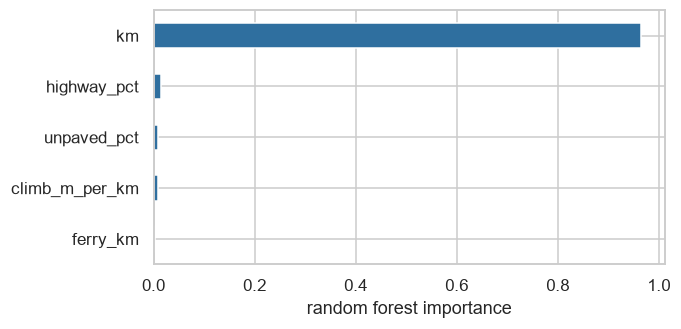

hours per extra 100 km (distance only): 1.32


In [14]:
rf = RandomForestRegressor(300, random_state=0, min_samples_leaf=2).fit(X, y)
imp = pd.Series(rf.feature_importances_, X.columns).sort_values()
imp.plot.barh(color="#2f6f9f", figsize=(6, 3)); plt.xlabel("random forest importance"); plt.show()

lin = LinearRegression().fit(X[["km"]], y)
print("hours per extra 100 km (distance only):", round(lin.coef_[0] * 100, 2))

In [15]:
df["pred_h"] = cross_val_predict(RandomForestRegressor(300, random_state=0, min_samples_leaf=2), X, y, cv=cv)
df["resid_h"] = df.hours - df.pred_h
df.reindex(df.resid_h.abs().sort_values(ascending=False).index)[["name", "region", "km", "unpaved_pct", "hours", "pred_h", "resid_h"]].round(1).head(6)

,name,region,km,unpaved_pct,hours,pred_h,resid_h
61,Cross-Canada Epic: Toronto to Vancouver,North America,5844.6,0.1,75.4,38.5,36.9
65,Namibia Desert and Wildlife Loop,Africa,1886.7,41.1,35.5,25.4,10.1
69,Top Gear Patagonia Special: Bariloche to Ushuaia,South America,3623.7,5.5,54.6,47.1,7.6
19,"Sydney to Melbourne via Blue Mountains, Snowy ...",Oceania,2097.1,0.0,28.0,35.4,-7.4
73,Top Gear Vietnam Special: Saigon to Ha Long Bay,Asia,2587.7,0.0,36.0,43.0,-7.0
62,From Dallas to the Teton Rockies,North America,2982.7,0.0,37.0,43.7,-6.7


## 7. Do trips fall into natural groups?

K-means on standardised pacing and road features. The silhouette scores are low and flat (0.23 to 0.26), so there is no
sharp cluster structure. The split into two groups is a gradient: faster highway-heavy trips against slower, steeper,
winding ones.

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

feat = ["km_per_day", "avg_kmh", "highway_pct", "unpaved_pct", "climb_m_per_km", "days"]
Z = StandardScaler().fit_transform(df[feat].fillna(0))
scores = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z)) for k in range(2, 8)}
print({k: round(v, 3) for k, v in scores.items()})
k = max(scores, key=scores.get)
df["cluster"] = KMeans(k, n_init=10, random_state=0).fit_predict(Z)
print("chosen k =", k)
df.groupby("cluster")[feat].median().round(1).assign(trips=df.cluster.value_counts().sort_index())

{2: 0.263, 3: 0.257, 4: 0.236, 5: 0.259, 6: 0.233, 7: 0.228}
chosen k = 2


,km_per_day,avg_kmh,highway_pct,unpaved_pct,climb_m_per_km,days,trips
cluster,,,,,,,
0,274.5,71.8,25.1,0.1,12.5,5.0,47
1,146.5,56.9,4.8,0.3,20.3,5.0,27


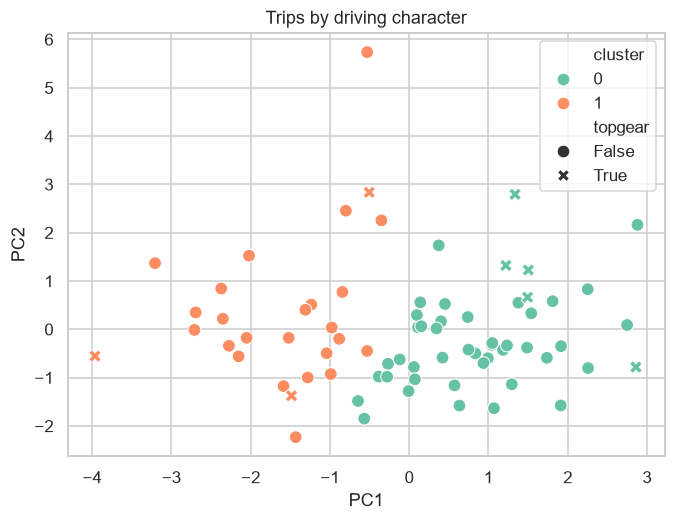

0 | Pacific Coast Odyssey: Seattle to San , Scottish Highlands and North Coast 500, From Dallas to the Teton Rockies, 6-Day Yucatán Peninsula Cultural and C
1 | Costa Rica Volcanoes and Coastline Roa, Mae Hong Son Loop Expedition, Salta and the Quebrada Wonders, Swiss Alps Triple Pass Loop


In [17]:
P = PCA(2).fit_transform(Z)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df.cluster, palette="Set2", style=df.topgear, s=70)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Trips by driving character"); plt.show()
for c, g in df.groupby("cluster"):
    print(c, "|", ", ".join(g.sample(min(4, len(g)), random_state=1).name.str.slice(0, 38)))

## 8. Where the trips are

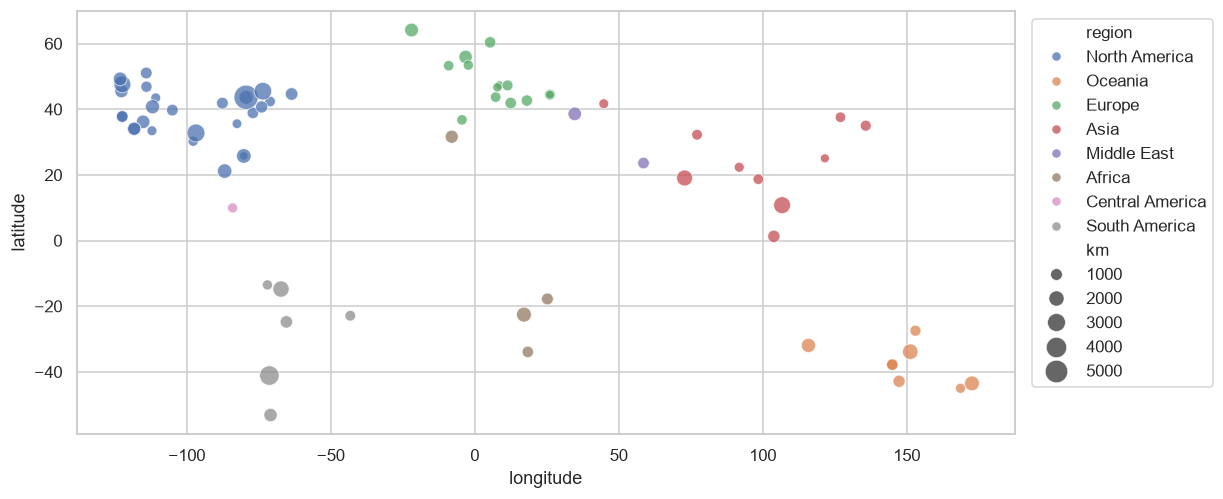

In [18]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x="lng", y="lat", hue="region", size="km", sizes=(30, 250), alpha=.75)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.show()

## 9. How good is the planner, and what does the pipeline fix?

The trips above are the finished product. The app's planner works in stages: the model drafts a plan, a checker finds
problems and asks for one repair, stops are geocoded, routed, extra points are added on featured roads the route misses
("road pass"), and a dynamic program moves overnights so no day runs long. `tools/eval-planner.mjs` ran 30 fixed trip
requests through that pipeline and logged every stage (results in `eval/results/`). Here the logs are analysed with
bootstrap intervals (resampling requests).

Two of the three models are compared. The third (`gemini-flash-latest`) failed 62% of requests on busy-server errors, so
its numbers rest on too few trips to compare.

In [19]:
import glob, os
run = sorted(glob.glob("../eval/results/*/"))[-1]
logs = {os.path.basename(p)[:-6]: pd.read_json(p, lines=True) for p in glob.glob(run + "*.jsonl")}
logs = {k: v for k, v in logs.items() if k != "gemini-flash-latest"}
rng = np.random.default_rng(0)

def boot(frame, stat, n=2000):
    vals = [stat(frame.iloc[rng.integers(0, len(frame), len(frame))]) for _ in range(n)]
    return stat(frame), np.nanpercentile(vals, 2.5), np.nanpercentile(vals, 97.5)

rows = []
for model, L in logs.items():
    ok = L[L.get("error").isna()] if "error" in L else L
    ok = ok.dropna(subset=["roadsTotal"]).copy()
    ok["driven_before"] = ok.roadsTotal - ok.undrivenBefore.apply(len)
    ok["driven_after"] = ok.roadsTotal - ok.undrivenAfter.apply(len)
    ok["maxh_before"] = ok.hoursBefore.apply(max); ok["maxh_after"] = ok.hoursAfter.apply(max)
    for label, stat in [
        ("featured roads driven, before road pass (%)", lambda f: 100 * f.driven_before.sum() / f.roadsTotal.sum()),
        ("featured roads driven, after road pass (%)", lambda f: 100 * f.driven_after.sum() / f.roadsTotal.sum()),
        ("trips with a day over the limit, before (%)", lambda f: 100 * (f.longBefore > 0).mean()),
        ("trips with a day over the limit, after (%)", lambda f: 100 * (f.longAfter > 0).mean()),
        ("longest day before day-split (h)", lambda f: f.maxh_before.mean()),
        ("longest day after day-split (h)", lambda f: f.maxh_after.mean()),
        ("distance saved by reordering stops (km, mean)", lambda f: f.viterbiKmSaved.mean()),
    ]:
        v, lo, hi = boot(ok, stat)
        rows.append(dict(model=model, n=len(ok), metric=label, value=v, lo=lo, hi=hi))
res = pd.DataFrame(rows)
print({m: f"{len(L)} requests, {len(L) - len(L[L.get('error').isna()]) if 'error' in L else 0} failed" for m, L in logs.items()})
res.pivot(index="metric", columns="model", values="value").round(1)

{'gemini-3.1-flash-lite': '30 requests, 3 failed', 'gemini-flash-lite-latest': '30 requests, 4 failed'}


model,gemini-3.1-flash-lite,gemini-flash-lite-latest
metric,,
"distance saved by reordering stops (km, mean)",200.5,224.2
"featured roads driven, after road pass (%)",68.8,89.7
"featured roads driven, before road pass (%)",65.6,79.5
longest day after day-split (h),4.8,5.4
longest day before day-split (h),5.6,6.3
"trips with a day over the limit, after (%)",3.7,11.5
"trips with a day over the limit, before (%)",18.5,19.2


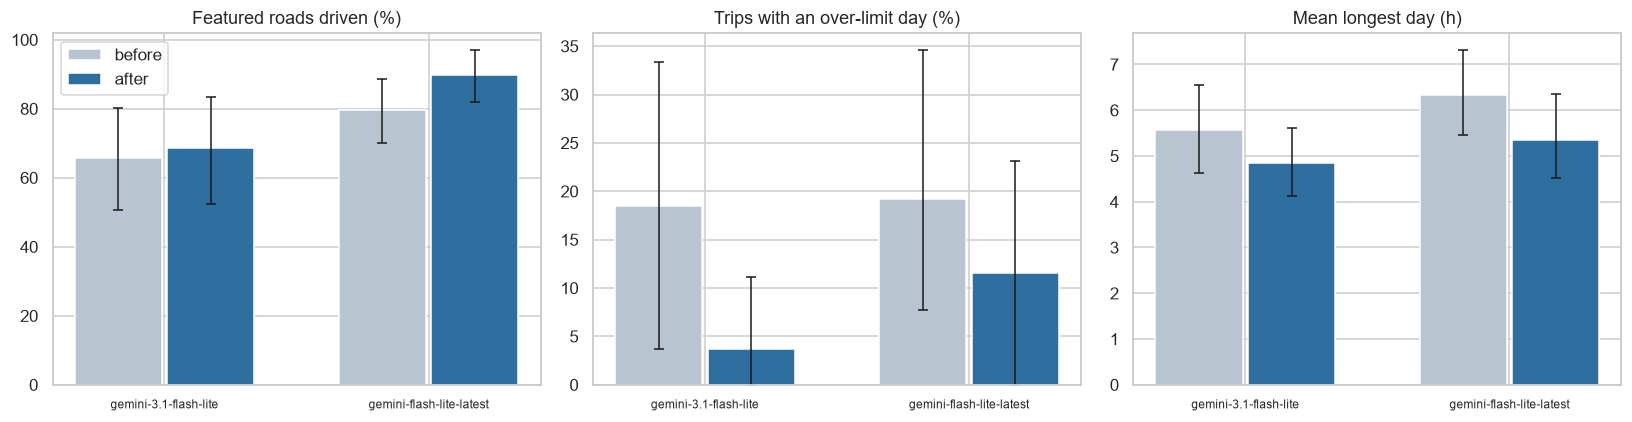

In [20]:
pairs = [("featured roads driven, before road pass (%)", "featured roads driven, after road pass (%)", "Featured roads driven (%)"),
         ("trips with a day over the limit, before (%)", "trips with a day over the limit, after (%)", "Trips with an over-limit day (%)"),
         ("longest day before day-split (h)", "longest day after day-split (h)", "Mean longest day (h)")]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (b, a, ttl) in zip(axs, pairs):
    for j, (model, g) in enumerate(res.groupby("model")):
        for k, (lab, m) in enumerate([("before", b), ("after", a)]):
            r = g[g.metric == m].iloc[0]
            x = j + (k - .5) * .35
            ax.bar(x, r.value, .33, color=["#b8c4cf", "#2f6f9f"][k], label=lab if j == 0 else None)
            ax.errorbar(x, r.value, yerr=[[r.value - r.lo], [r.hi - r.value]], c="k", lw=1, capsize=3)
    ax.set_xticks(range(len(logs))); ax.set_xticklabels(list(logs), fontsize=8); ax.set_title(ttl)
axs[0].legend(); plt.tight_layout(); plt.show()

Read it as an ablation: each bar pair is the same requests before and after one pipeline stage. Both stages move the
numbers in the intended direction: more featured roads driven after the road pass (about +3 and +10 points), and fewer
trips with an over-limit day after the day split (about 19% down to 4% and 12%). But the intervals overlap, so with 30
requests this is evidence of direction, not proof of size. Running each request several times (`--repeat`) would narrow
them. Differences under about 15 points between models are noise.

## Summary numbers

In [21]:
d = df.dropna(subset=["fast_km"])
print(f"- {len(df)} trips in {df.region.nunique()} regions, median {df.km.median():.0f} km over {df.days.median():.0f} days.")
print(f"- Median scenic detour: {d.detour_km_pct.median():.1f}% more distance, {d.extra_min.median():.0f} extra minutes over the fastest route.")
print(f"- {(df.max_day_h > 8).sum()} trips have a driving day above 8 hours; highest median longest day: {df.groupby('region').max_day_h.median().idxmax()}.")
print(f"- Distance alone explains drive time with cross-validated R2 about {cross_val_score(LinearRegression(), df[['km']], df.hours, cv=cv, scoring='r2').mean():.2f}.")
df.drop(columns=["pred_h", "resid_h"]).to_csv("trip_features.csv", index=False)
print("- Saved the table as trip_features.csv.")

- 74 trips in 8 regions, median 946 km over 5 days.
- Median scenic detour: 11.0% more distance, 136 extra minutes over the fastest route.
- 2 trips have a driving day above 8 hours; highest median longest day: South America.
- Distance alone explains drive time with cross-validated R2 about 0.94.
- Saved the table as trip_features.csv.
